# Análise exploratória de vendas · Loja Horizonte

E-commerce fictício, ano de 2025. Objetivo: limpar a base de pedidos e responder onde está a receita, como ela varia no ano e quais canais e segmentos merecem atenção.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

pedidos  = pd.read_csv('dados/pedidos.csv', parse_dates=['data'])
clientes = pd.read_csv('dados/clientes.csv')
itens    = pd.read_csv('dados/itens_pedido.csv')
produtos = pd.read_csv('dados/produtos.csv')
pedidos.head()

,id,cliente_id,vendedor_id,data,canal,status,valor_total
0,1,76,6,2025-07-18,Site,Entregue,534.18
1,2,191,5,2025-12-07,Site,Entregue,192.50
2,3,148,2,2025-09-04,Site,Entregue,138.59
3,4,92,2,2025-02-11,App,Entregue,722.99
4,5,225,7,2025-01-25,Marketplace,Entregue,200.05


## 1. Qualidade dos dados

In [2]:
print(pedidos.shape)
print(pedidos.dtypes, '\n')
print('Nulos por coluna:\n', pedidos.isna().sum(), '\n')
print('IDs duplicados:', pedidos['id'].duplicated().sum())
pedidos['status'].value_counts()

(3000, 7)
id                      int64
cliente_id              int64
vendedor_id             int64
data           datetime64[us]
canal                     str
status                    str
valor_total           float64
dtype: object 

Nulos por coluna:
 id             0
cliente_id     0
vendedor_id    0
data           0
canal          0
status         0
valor_total    0
dtype: int64 

IDs duplicados: 0


status
Entregue     2688
Cancelado     174
Devolvido     138
Name: count, dtype: int64

A base não tem nulos nem IDs repetidos. Pedidos **cancelados** não geram receita, então saem da análise de faturamento. Devolvidos ficam, porque a venda aconteceu.

In [3]:
validos = pedidos[pedidos['status'] != 'Cancelado'].copy()
print(f'{len(validos):,} pedidos válidos de {len(pedidos):,} ({len(pedidos) - len(validos)} cancelados)')

2,826 pedidos válidos de 3,000 (174 cancelados)


## 2. Valores fora do padrão (intervalo interquartil)

In [4]:
q1, q3 = validos['valor_total'].quantile([.25, .75])
iqr = q3 - q1
limite = q3 + 1.5 * iqr
validos['outlier'] = validos['valor_total'] > limite
print(f'Q1 = {q1:,.2f} | Q3 = {q3:,.2f} | limite superior = {limite:,.2f}')
print(f"{validos['outlier'].sum()} pedidos acima do limite ({validos['outlier'].mean():.1%})")
validos.loc[validos['outlier'], 'valor_total'].describe()

Q1 = 140.22 | Q3 = 415.03 | limite superior = 827.24
217 pedidos acima do limite (7.7%)


count     217.00
mean    1,169.14
std       391.89
min       829.64
25%       916.66
50%     1,041.93
75%     1,291.63
max     4,127.69
Name: valor_total, dtype: float64

Os valores altos são compras reais de eletrônicos e de clientes Premium, não erros de digitação. Por isso **marco** esses pedidos em vez de apagar: eles entram no faturamento, mas ficam fora das médias de ticket para não distorcer.

## 3. Juntando as tabelas

In [5]:
base = (validos
        .merge(clientes[['id', 'regiao', 'segmento']], left_on='cliente_id', right_on='id', suffixes=('', '_cli'))
        .merge(itens[['pedido_id', 'produto_id', 'quantidade']], left_on='id', right_on='pedido_id')
        .merge(produtos[['id', 'categoria']], left_on='produto_id', right_on='id', suffixes=('', '_prod'))
        [['id', 'data', 'canal', 'status', 'valor_total', 'outlier', 'regiao', 'segmento', 'categoria', 'quantidade']])
base['mes'] = base['data'].dt.to_period('M')
base.head()

,id,data,canal,status,valor_total,outlier,regiao,segmento,categoria,quantidade,mes
0,1,2025-07-18,Site,Entregue,534.18,False,Nordeste,Atacado,Moda,1,2025-07
1,2,2025-12-07,Site,Entregue,192.50,False,Sul,Premium,Moda,3,2025-12
2,3,2025-09-04,Site,Entregue,138.59,False,Sudeste,Varejo,Moda,2,2025-09
3,4,2025-02-11,App,Entregue,722.99,False,Sudeste,Varejo,Eletrônicos,1,2025-02
4,5,2025-01-25,Marketplace,Entregue,200.05,False,Centro-Oeste,Varejo,Moda,3,2025-01


## 4. Receita ao longo do ano

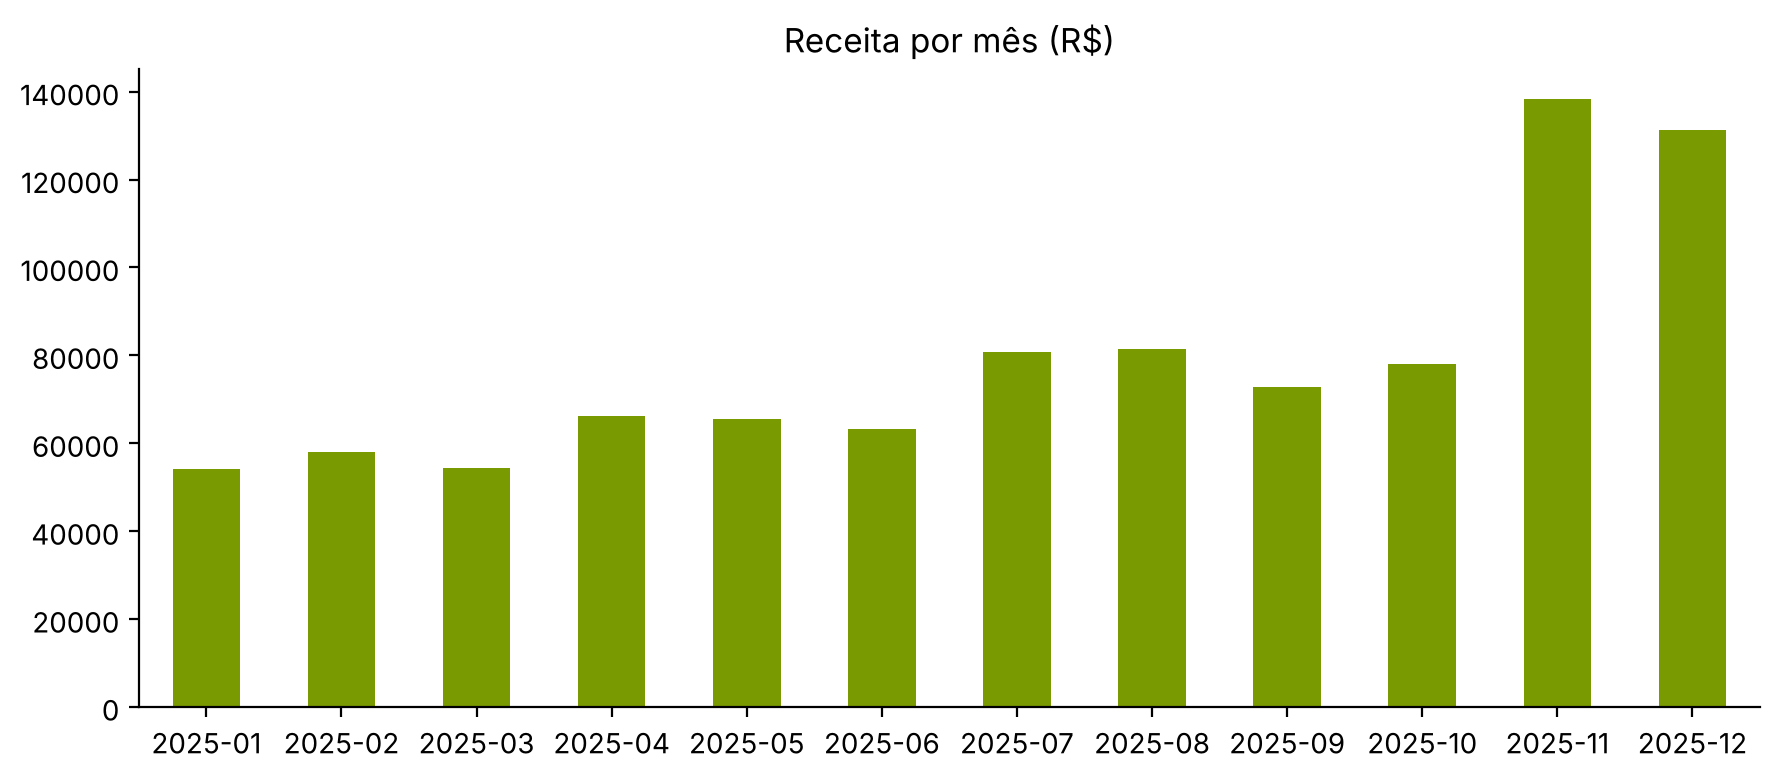

,receita,crescimento_%
mes,,
2025-01,"54,118.97",NaN
2025-02,"57,916.75",7.00
2025-03,"54,354.98",-6.10
2025-04,"66,205.56",21.80
2025-05,"65,593.04",-0.90
2025-06,"63,282.92",-3.50
2025-07,"80,711.77",27.50
2025-08,"81,421.00",0.90
2025-09,"72,751.22",-10.60


In [6]:
mensal = base.groupby('mes')['valor_total'].sum()
cresc = mensal.pct_change() * 100
resumo = pd.DataFrame({'receita': mensal, 'crescimento_%': cresc.round(1)})
ax = mensal.plot(kind='bar', color='#7a9a01', title='Receita por mês (R$)')
ax.set_xlabel(''); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('graficos/receita_mensal.png', dpi=120); plt.show()
resumo

In [7]:
fim_ano = mensal.iloc[-2:].sum() / mensal.sum()
print(f'Novembro e dezembro concentram {fim_ano:.0%} da receita do ano.')

Novembro e dezembro concentram 29% da receita do ano.


## 5. Categoria, canal e segmento

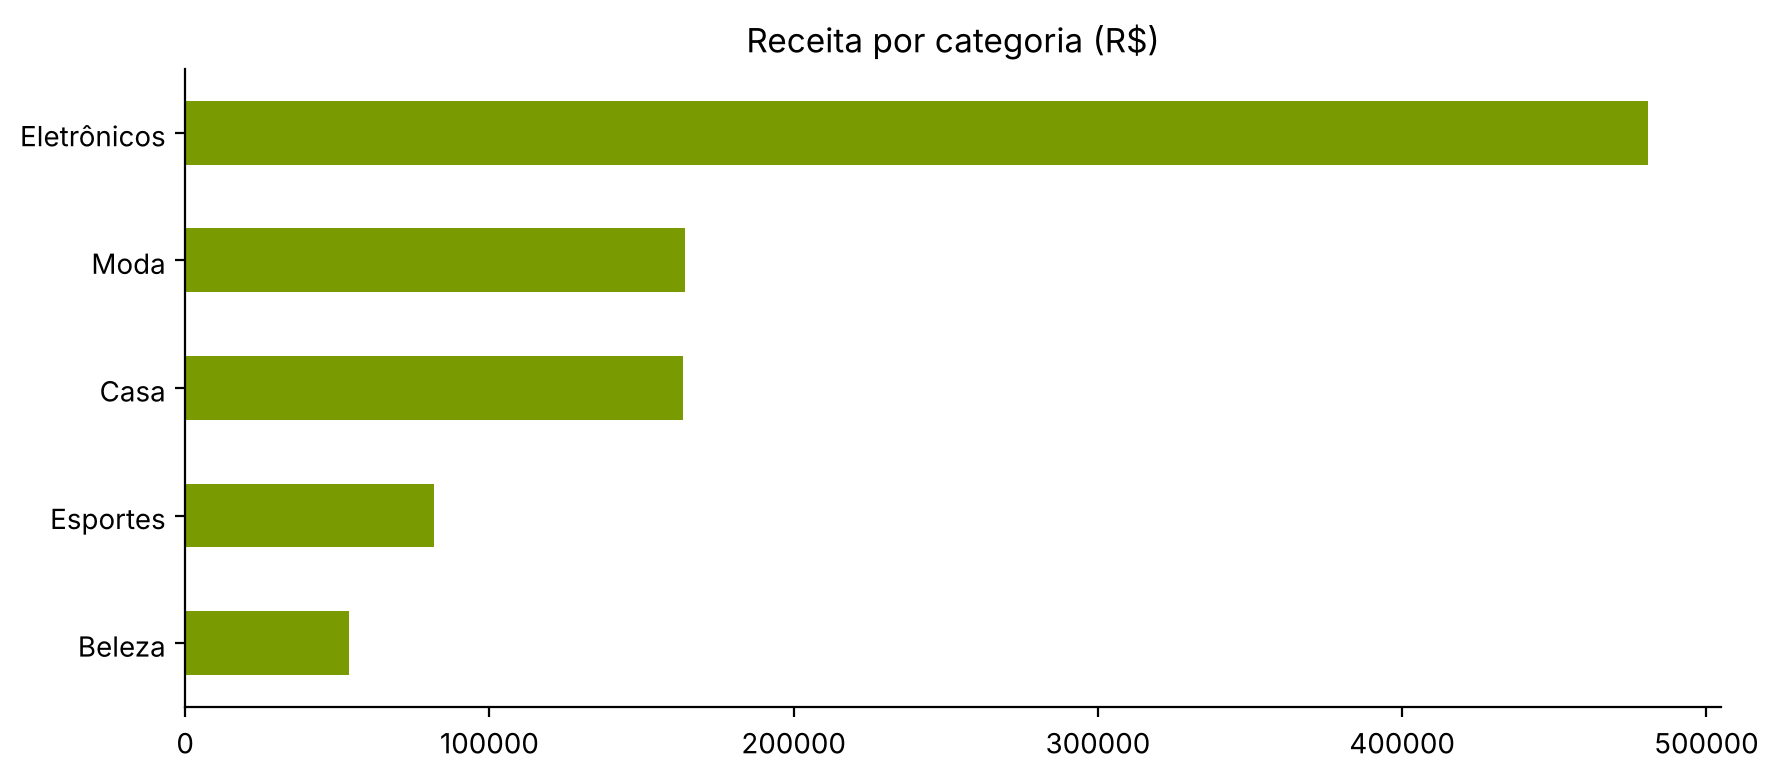

,pedidos,receita,participacao_%
categoria,,,
Eletrônicos,648,"480,726.94",50.90
Moda,836,"164,150.31",17.40
Casa,556,"163,601.32",17.30
Esportes,334,"81,809.68",8.70
Beleza,452,"53,709.58",5.70


In [8]:
cat = base.groupby('categoria').agg(pedidos=('id', 'count'), receita=('valor_total', 'sum')).sort_values('receita', ascending=False)
cat['participacao_%'] = (cat['receita'] / cat['receita'].sum() * 100).round(1)
ax = cat['receita'].plot(kind='barh', color='#7a9a01', title='Receita por categoria (R$)')
ax.invert_yaxis(); ax.set_ylabel(''); plt.tight_layout(); plt.savefig('graficos/receita_categoria.png', dpi=120); plt.show()
cat

In [9]:
sem_outlier = base[~base['outlier']]
pd.pivot_table(sem_outlier, values='valor_total', index='segmento', columns='canal', aggfunc='mean').round(2)

canal,App,Marketplace,Site
segmento,,,
Atacado,270.80,249.71,256.86
Premium,319.50,296.12,306.80
Varejo,268.19,247.95,252.02


In [10]:
canc = pedidos.groupby('canal')['status'].apply(lambda s: (s == 'Cancelado').mean() * 100).round(1).sort_values(ascending=False)
canc.rename('cancelamento_%')

canal
Marketplace   7.00
App           5.80
Site          5.20
Name: cancelamento_%, dtype: float64

## Conclusões

1. **Eletrônicos traz cerca de metade da receita**, mesmo com menos pedidos que Moda. Ruptura de estoque nessa categoria tem o maior impacto.
2. **Novembro e dezembro concentram 29% do ano.** Estoque, frete e atendimento precisam ser reforçados a partir de outubro.
3. **Clientes Premium têm o maior ticket médio em todos os canais**, um público bom para campanhas de fidelidade.
4. **O Marketplace cancela mais que Site e App.** Vale investigar prazo de entrega e descrição dos anúncios nesse canal.